## Phase 2: Datasaurus Dozen Statistical Validation
**Objective:** Calculate mean, variance, Pearson correlation, and least-squares regression for all 13 Datasaurus subsets to prove they share identical summary statistics despite differing spatial geometries.

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [83]:
df = pd.read_csv('../Data/Cleaned_Data/datasaurus_clean.csv')
print(df.columns)
print()
print(df["dataset"].unique())  
print()
print(df["dataset"].value_counts())

Index(['dataset', 'x', 'y'], dtype='object')

['dino' 'away' 'h_lines' 'v_lines' 'x_shape' 'star' 'high_lines' 'dots'
 'circle' 'bullseye' 'slant_up' 'slant_down' 'wide_lines']

dataset
dino          142
away          142
h_lines       142
v_lines       142
x_shape       142
star          142
high_lines    142
dots          142
circle        142
bullseye      142
slant_up      142
slant_down    142
wide_lines    142
Name: count, dtype: int64


In [84]:
def compute_mean(arr: np.ndarray) -> float:
    return np.sum(arr) / len(arr)


def compute_sample_variance(arr: np.ndarray, mean_val: float) -> float:
    return np.sum((arr - mean_val) ** 2) / (len(arr) - 1)


def compute_correlation(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> float:
    numerator = np.sum((x - mean_x) * (y - mean_y))
    denominator = np.sqrt(np.sum((x - mean_x) ** 2) * np.sum((y - mean_y) ** 2) )
    return numerator / denominator


def compute_linear_regression(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> tuple[float, float]:
    beta_1 = np.sum((x - mean_x) * (y - mean_y)) / np.sum((x - mean_x) ** 2)
    beta_0 = mean_y - (beta_1 * mean_x)
    return beta_0, beta_1

### Stats of subset: dino

In [85]:
dino = df[df['dataset'] == 'dino']
dino

,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333
...,...,...,...
137,dino,39.4872,25.3846
138,dino,91.2821,41.5385
139,dino,50.0000,95.7692
140,dino,47.9487,95.0000


In [86]:
dino_mean_x = compute_mean(dino['x'])
dino_mean_y = compute_mean(dino['y'])
print(f"Mean x: {dino_mean_x} | Mean y: {dino_mean_y}")

Mean x: 54.26327323943662 | Mean y: 47.832252816901416


In [87]:
dino_var_x = compute_sample_variance(dino['x'].values, dino_mean_x)
dino_var_y = compute_sample_variance(dino['y'].values, dino_mean_y)
print(f"Var x: {dino_var_x} | Var y: {dino_var_y}")

Var x: 281.069987591761 | Var y: 725.5159610042118


In [88]:
dino_pearson_xy = compute_correlation(dino['x'].values, dino['y'].values, dino_mean_x, dino_mean_y)
print(f"Pearson r: {dino_pearson_xy}")

Pearson r: -0.06447185270095167


In [89]:
dino_slope = compute_linear_regression(dino['x'].values, dino['y'].values, dino_mean_x, dino_mean_y)
print(f"Slope: {dino_slope}")

Slope: (53.452978449229235, -0.10358250243265602)


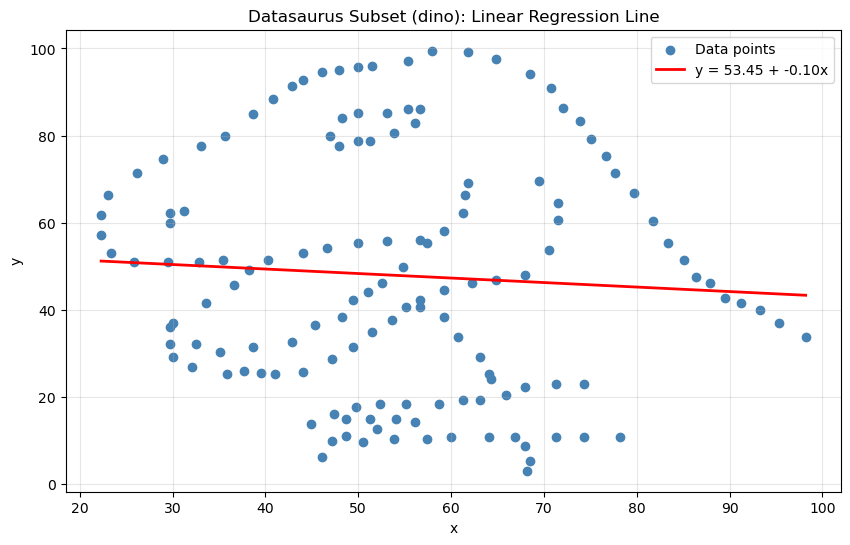

In [90]:
x_line = np.linspace(dino["x"].min(), dino["x"].max(), 100)
y_line = dino_slope[0] + dino_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(dino["x"], dino["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {dino_slope[0]:.2f} + {dino_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (dino): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('dino.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### Stats of subset: away

In [91]:
away = df[df['dataset'] == 'away']
away

,dataset,x,y
142,away,32.331110,61.411101
143,away,53.421463,26.186880
144,away,63.920202,30.832194
145,away,70.289506,82.533649
146,away,34.118830,45.734551
...,...,...,...
279,away,59.851838,72.958391
280,away,48.960460,72.629526
281,away,46.844855,36.791714
282,away,39.963022,42.944915


In [92]:
away_mean_x = compute_mean(away['x'])
away_mean_y = compute_mean(away['y'])
print(f"Mean x: {away_mean_x} | Mean y: {away_mean_y}")

Mean x: 54.266099784204926 | Mean y: 47.83472062488412


In [93]:
away_var_x = compute_sample_variance(away['x'], away_mean_x)
away_var_y = compute_sample_variance(away['y'], away_mean_y)
print(f"Var x: {away_var_x} | Var y: {away_var_y}")

Var x: 281.2270289930791 | Var y: 725.7497754752688


In [94]:
away_pearson_xy = compute_correlation(away["x"],away['y'],away_mean_x,away_mean_y)
print(f"Pearson r: {away_pearson_xy}")

Pearson r: -0.0641283521547448


In [95]:
away_slope = compute_linear_regression(away["x"],away['y'],away_mean_x,away_mean_y)
print(f"Slope: {away_slope}")

Slope: (53.4251300454603, -0.10301844877017245)


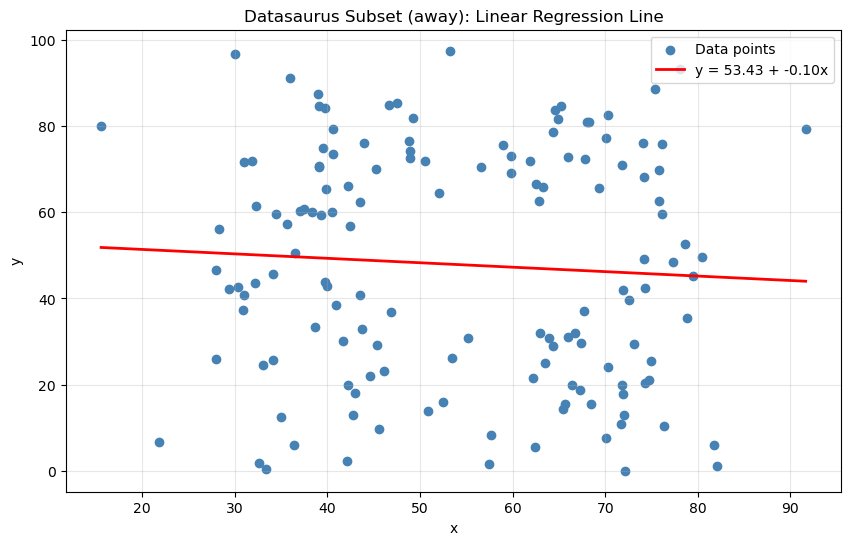

In [96]:
x_line = np.linspace(away["x"].min(), away["x"].max(), 100)
y_line = away_slope[0] + away_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(away["x"], away["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {away_slope[0]:.2f} + {away_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (away): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: h_lines

In [97]:
h_lines = df[df['dataset'] == 'h_lines']
h_lines

,dataset,x,y
284,h_lines,53.366567,90.208030
285,h_lines,52.801979,90.088065
286,h_lines,47.054130,90.458936
287,h_lines,42.448434,89.507700
288,h_lines,42.704036,90.442629
...,...,...,...
421,h_lines,42.224120,30.498037
422,h_lines,87.698464,50.489937
423,h_lines,52.360331,89.704317
424,h_lines,51.406787,89.712139


In [98]:
h_lines_mean_x = compute_mean(h_lines['x'])
h_lines_mean_y = compute_mean(h_lines['y'])
print(f"Mean x: {h_lines_mean_x} | Mean y: {h_lines_mean_y}")

Mean x: 54.261441783514094 | Mean y: 47.830251913635216


In [99]:
h_lines_var_x = compute_sample_variance(h_lines['x'], h_lines_mean_x)
h_lines_var_y = compute_sample_variance(h_lines['y'], h_lines_mean_y)
print(f"Var x: {h_lines_var_x} | Var y: {h_lines_var_y}")

Var x: 281.09533252964826 | Var y: 725.7569307510677


In [100]:
h_lines_pearson_xy = compute_correlation(h_lines["x"],h_lines['y'],h_lines_mean_x,h_lines_mean_y)
print(f"Pearson r: {h_lines_pearson_xy}")

Pearson r: -0.061714837956677766


In [101]:
h_lines_slope = compute_linear_regression(h_lines["x"],h_lines['y'],h_lines_mean_x,h_lines_mean_y)
print(f"Slope: {h_lines_slope}")

Slope: (53.21108723737491, -0.09916498985057419)


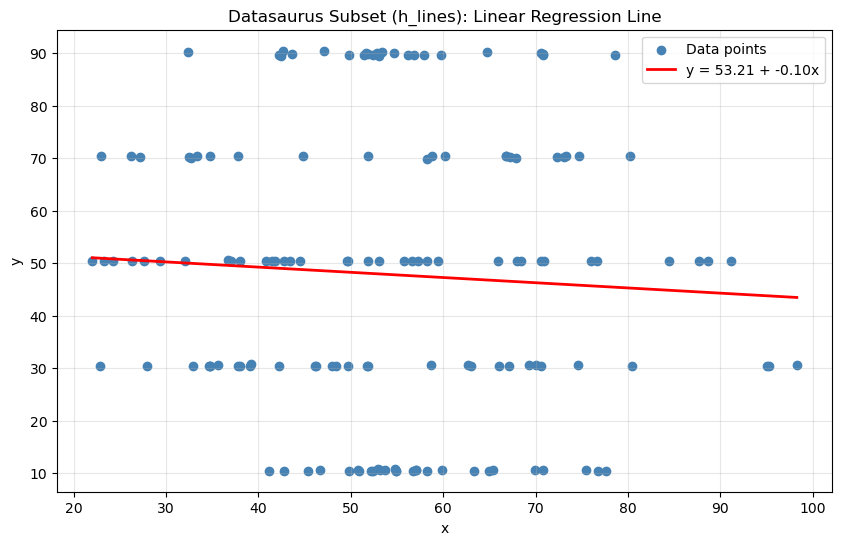

In [102]:
x_line = np.linspace(h_lines["x"].min(), h_lines["x"].max(), 100)
y_line = h_lines_slope[0] + h_lines_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(h_lines["x"], h_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {h_lines_slope[0]:.2f} + {h_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (h_lines): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: v_lines

In [103]:
v_lines = df[df['dataset'] == 'v_lines']
v_lines

,dataset,x,y
426,v_lines,50.481508,93.222701
427,v_lines,50.282406,97.609984
428,v_lines,50.186703,99.694680
429,v_lines,50.326911,90.022053
430,v_lines,50.456207,89.987410
...,...,...,...
563,v_lines,30.487392,19.779470
564,v_lines,89.500180,31.978917
565,v_lines,50.410272,98.628369
566,v_lines,50.325924,94.994631


In [104]:
v_lines_mean_x = compute_mean(v_lines['x'])
v_lines_mean_y = compute_mean(v_lines['y'])
print(f"Mean x: {v_lines_mean_x} | Mean y: {v_lines_mean_y}")

Mean x: 54.26992723102747 | Mean y: 47.83698798816881


In [105]:
v_lines_var_x = compute_sample_variance(v_lines['x'], v_lines_mean_x)
v_lines_var_y = compute_sample_variance(v_lines['y'], v_lines_mean_y)
print(f"Var x: {v_lines_var_x} | Var y: {v_lines_var_y}")

Var x: 281.2315118265872 | Var y: 725.6388088845063


In [106]:
v_lines_pearson_xy = compute_correlation(v_lines["x"],v_lines['y'],v_lines_mean_x,v_lines_mean_y)
print(f"Pearson r: {v_lines_pearson_xy}")

Pearson r: -0.06944556959817211


In [107]:
v_lines_slope = compute_linear_regression(v_lines["x"],v_lines['y'],v_lines_mean_x,v_lines_mean_y)
print(f"Slope: {v_lines_slope}")

Slope: (53.890843393692265, -0.11155082961051624)


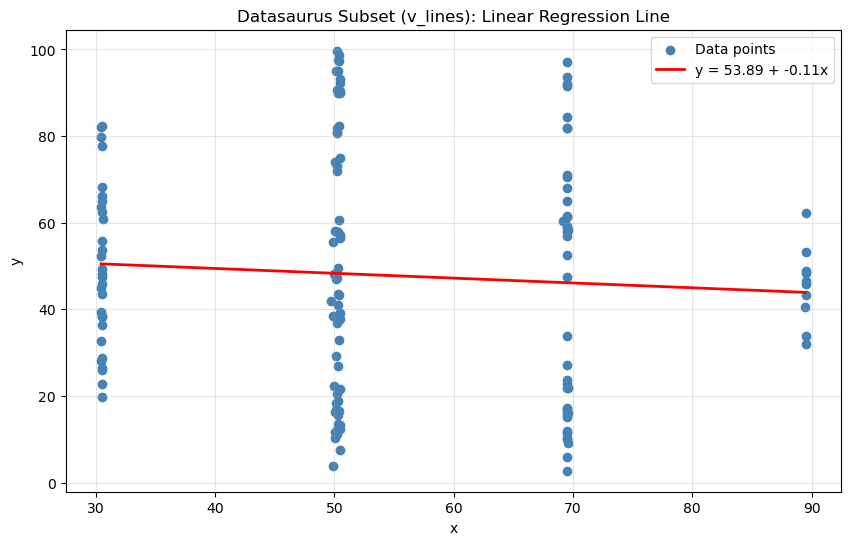

In [108]:
x_line = np.linspace(v_lines["x"].min(), v_lines["x"].max(), 100)
y_line = v_lines_slope[0] + v_lines_slope[1] * x_line

plt.figure(figsize=(10,6))
plt.scatter(v_lines["x"], v_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red",
          linewidth=2, label=f"y = {v_lines_slope[0]:.2f} + {v_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (v_lines): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: x_shape

In [109]:
x_shape = df[df['dataset'] == 'x_shape']
x_shape

,dataset,x,y
568,x_shape,38.337757,92.472719
569,x_shape,35.751871,94.116768
570,x_shape,32.767218,88.518295
571,x_shape,33.729607,88.622266
572,x_shape,37.238249,83.724928
...,...,...,...
705,x_shape,34.794594,13.969683
706,x_shape,79.221764,22.094591
707,x_shape,36.030880,93.121733
708,x_shape,34.499558,86.609985


In [110]:
x_shape_mean_x = compute_mean(x_shape['x'])
x_shape_mean_y = compute_mean(x_shape['y'])
print(f"Mean x: {x_shape_mean_x} | Mean y: {x_shape_mean_y}")

Mean x: 54.26015033403803 | Mean y: 47.839717279160425


In [111]:
x_shape_var_x = compute_sample_variance(x_shape['x'], x_shape_mean_x)
x_shape_var_y = compute_sample_variance(x_shape['y'], x_shape_mean_y)
print(f"Var x: {x_shape_var_x} | Var y: {x_shape_var_y}")

Var x: 281.2314811195686 | Var y: 725.2249908607989


In [112]:
x_shape_pearson_xy = compute_correlation(x_shape["x"], x_shape['y'], x_shape_mean_x, x_shape_mean_y)
print(f"Pearson r: {x_shape_pearson_xy}")

Pearson r: -0.0655833373100655


In [113]:
x_shape_slope = compute_linear_regression(x_shape["x"], x_shape['y'], x_shape_mean_x, x_shape_mean_y)
x_shape_slope
print(f"Slope: {x_shape_slope}")

Slope: (53.55422625106995, -0.10531686581643593)


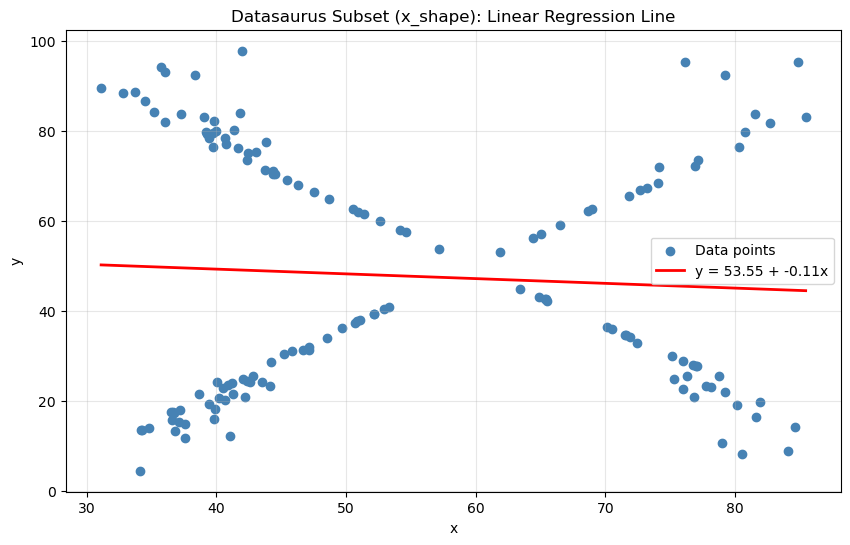

In [114]:
x_line = np.linspace(x_shape["x"].min(), x_shape["x"].max(), 100)
y_line = x_shape_slope[0] + x_shape_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(x_shape["x"], x_shape["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {x_shape_slope[0]:.2f} + {x_shape_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (x_shape): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: star

In [115]:
star = df[df['dataset'] == 'star']
star

,dataset,x,y
710,star,58.213608,91.881892
711,star,58.196054,92.214989
712,star,58.718231,90.310532
713,star,57.278373,89.907607
714,star,58.082020,92.008145
...,...,...,...
847,star,43.722551,19.077328
848,star,79.326078,52.900391
849,star,56.663974,87.940125
850,star,57.821789,90.693167


In [116]:
star_mean_x = compute_mean(star['x'])
star_mean_y = compute_mean(star['y'])
print(f"Mean x: {star_mean_x} | Mean y: {star_mean_y}")

Mean x: 54.26734110449506 | Mean y: 47.839545225097886


In [117]:
star_var_x = compute_sample_variance(star['x'], star_mean_x)
star_var_y = compute_sample_variance(star['y'], star_mean_y)
print(f"Var x: {star_var_x} | Var y: {star_var_y}")

Var x: 281.1979931971459 | Var y: 725.239694752202


In [118]:
star_pearson_xy = compute_correlation(star["x"], star['y'], star_mean_x, star_mean_y)
print(f"Pearson r: {star_pearson_xy}")

Pearson r: -0.06296110022682307


In [119]:
star_slope = compute_linear_regression(star["x"], star['y'], star_mean_x, star_mean_y)
print(f"Slope: {star_slope}")

Slope: (53.32667872603676, -0.10111299704868651)


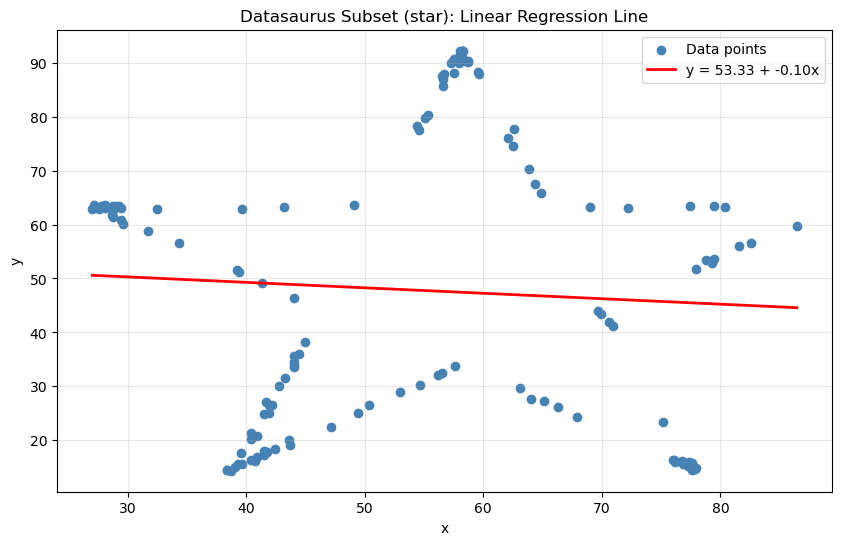

In [120]:
x_line = np.linspace(star["x"].min(), star["x"].max(), 100)
y_line = star_slope[0] + star_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(star["x"], star["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {star_slope[0]:.2f} + {star_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (star): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: high_lines

In [121]:
high_lines = df[df['dataset'] == 'high_lines']
high_lines

,dataset,x,y
852,high_lines,57.613234,83.905171
853,high_lines,51.274392,82.817983
854,high_lines,50.753898,76.754129
855,high_lines,37.021184,81.954470
856,high_lines,42.881755,80.184770
...,...,...,...
989,high_lines,37.949784,26.521749
990,high_lines,86.504391,34.894025
991,high_lines,50.815485,78.950839
992,high_lines,51.183467,85.128855


In [122]:
high_lines_mean_x = compute_mean(high_lines['x'])
high_lines_mean_y = compute_mean(high_lines['y'])
print(f"Mean x: {high_lines_mean_x} | Mean y: {high_lines_mean_y}")

Mean x: 54.26880527974154 | Mean y: 47.83545020393662


In [123]:
high_lines_var_x = compute_sample_variance(high_lines['x'], high_lines_mean_x)
high_lines_var_y = compute_sample_variance(high_lines['y'], high_lines_mean_y)
print(f"Var x: {high_lines_var_x} | Var y: {high_lines_var_y}")

Var x: 281.12236356582537 | Var y: 725.7634901501575


In [124]:
high_lines_pearson_xy = compute_correlation(high_lines["x"], high_lines['y'], high_lines_mean_x, high_lines_mean_y)
print(f"Pearson r: {high_lines_pearson_xy}")

Pearson r: -0.06850422050586688


In [125]:
high_lines_slope = compute_linear_regression(high_lines["x"], high_lines['y'], high_lines_mean_x, high_lines_mean_y)
print(f"Slope: {high_lines_slope}")

Slope: (53.808793163024305, -0.11006954968506605)


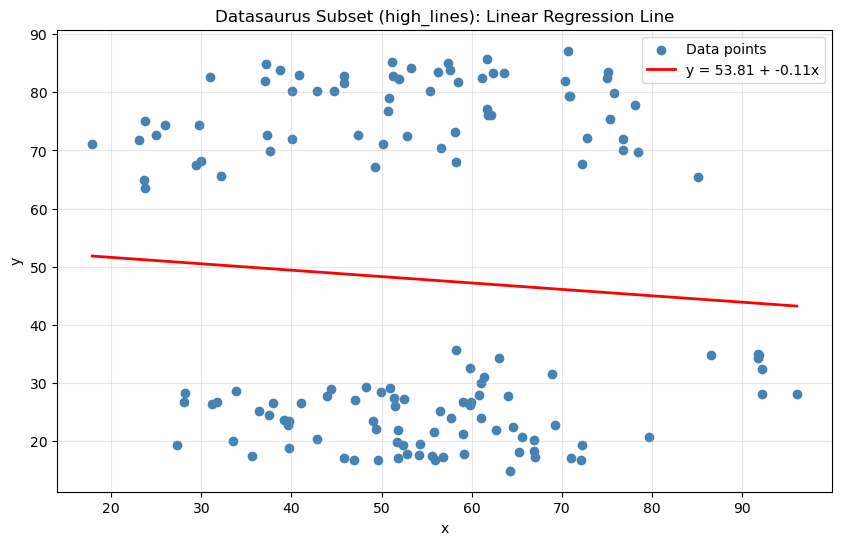

In [126]:
x_line = np.linspace(high_lines["x"].min(), high_lines["x"].max(), 100)
y_line = high_lines_slope[0] + high_lines_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(high_lines["x"], high_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {high_lines_slope[0]:.2f} + {high_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (high_lines): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: dots

In [127]:
dots = df[df['dataset'] == 'dots']
dots

,dataset,x,y
994,dots,51.147917,90.867412
995,dots,50.517126,89.102395
996,dots,50.207480,85.460047
997,dots,50.069482,83.057670
998,dots,50.562846,82.937822
...,...,...,...
1131,dots,50.533635,17.019581
1132,dots,77.500907,50.166986
1133,dots,50.691124,87.513960
1134,dots,49.990395,83.997357


In [128]:
dots_mean_x = compute_mean(dots['x'])
dots_mean_y = compute_mean(dots['y'])
print(f"Mean x: {dots_mean_x} | Mean y: {dots_mean_y}")

Mean x: 54.26030345121761 | Mean y: 47.83982920875564


In [129]:
dots_var_x = compute_sample_variance(dots['x'], dots_mean_x)
dots_var_y = compute_sample_variance(dots['y'], dots_mean_y)
print(f"Var x: {dots_var_x} | Var y: {dots_var_y}")

Var x: 281.15695341004164 | Var y: 725.2352152007652


In [130]:
dots_pearson_xy = compute_correlation(dots["x"], dots['y'], dots_mean_x, dots_mean_y)
print(f"Pearson r: {dots_pearson_xy}")

Pearson r: -0.060341441993538594


In [131]:
dots_slope = compute_linear_regression(dots["x"], dots['y'], dots_mean_x, dots_mean_y)
print(f"Slope: {dots_slope}")

Slope: (53.098341946502245, -0.09691270419219528)


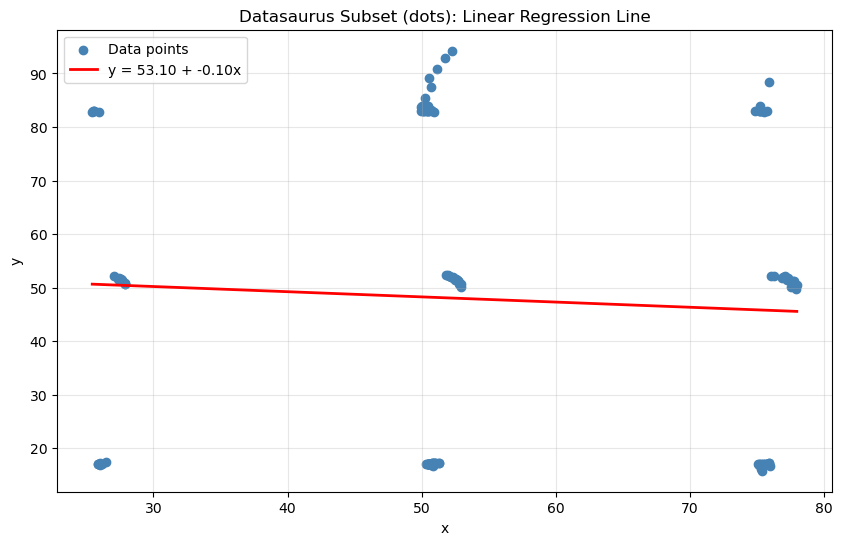

In [132]:
x_line = np.linspace(dots["x"].min(), dots["x"].max(), 100)
y_line = dots_slope[0] + dots_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(dots["x"], dots["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {dots_slope[0]:.2f} + {dots_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (dots): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: circle

In [133]:
circle = df[df['dataset'] == 'circle']
circle

,dataset,x,y
1136,circle,55.993030,79.277264
1137,circle,50.032254,79.013071
1138,circle,51.288459,82.435940
1139,circle,51.170537,79.165294
1140,circle,44.377915,78.164628
...,...,...,...
1273,circle,39.921363,19.701850
1274,circle,84.794278,55.568650
1275,circle,55.662959,83.356480
1276,circle,50.492248,78.997532


In [134]:
circle_mean_x = compute_mean(circle['x'])
circle_mean_y = compute_mean(circle['y'])
print(f"Mean x: {circle_mean_x} | Mean y: {circle_mean_y}")

Mean x: 54.267319706173936 | Mean y: 47.83771726721831


In [135]:
circle_var_x = compute_sample_variance(circle['x'], circle_mean_x)
circle_var_y = compute_sample_variance(circle['y'], circle_mean_y)
print(f"Var x: {circle_var_x} | Var y: {circle_var_y}")

Var x: 280.89802435237243 | Var y: 725.2268436918446


In [136]:
circle_pearson_xy = compute_correlation(circle["x"], circle['y'], circle_mean_x, circle_mean_y)
print(f"Pearson r: {circle_pearson_xy}")

Pearson r: -0.06834335645012027


In [137]:
circle_slope = compute_linear_regression(circle["x"], circle['y'], circle_mean_x, circle_mean_y)
print(f"Slope: {circle_slope}")

Slope: (53.79704498505452, -0.10981429984201387)


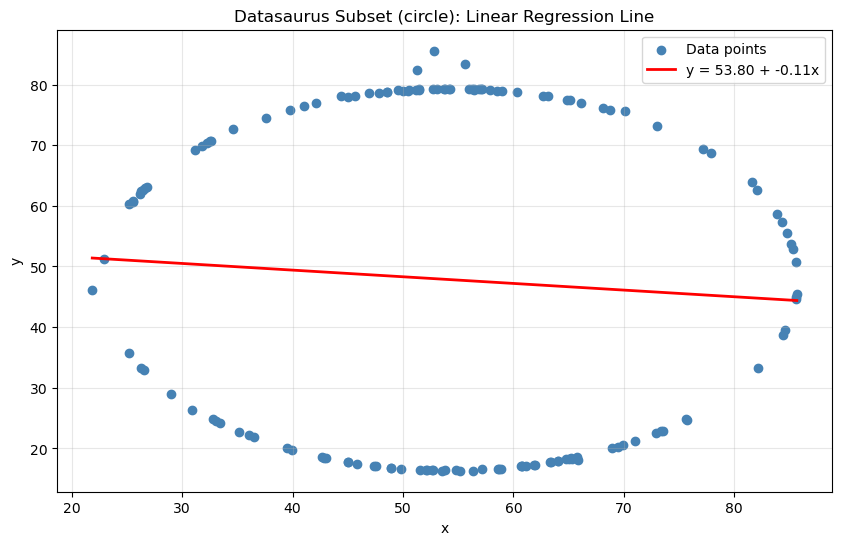

In [138]:
x_line = np.linspace(circle["x"].min(), circle["x"].max(), 100)
y_line = circle_slope[0] + circle_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(circle["x"], circle["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {circle_slope[0]:.2f} + {circle_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (circle): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: bullseye

In [139]:
bullseye = df[df['dataset'] == 'bullseye']
bullseye

,dataset,x,y
1278,bullseye,51.203891,83.339777
1279,bullseye,58.974470,85.499818
1280,bullseye,51.872073,85.829738
1281,bullseye,48.179931,85.045117
1282,bullseye,41.683200,84.017941
...,...,...,...
1415,bullseye,50.967748,29.679774
1416,bullseye,91.191054,46.674343
1417,bullseye,55.863768,85.336487
1418,bullseye,49.280595,84.048823


In [140]:
bullseye_mean_x = compute_mean(bullseye['x'])
bullseye_mean_y = compute_mean(bullseye['y'])
print(f"Mean x: {bullseye_mean_x} | Mean y: {bullseye_mean_y}")

Mean x: 54.268730022378875 | Mean y: 47.830823155217814


In [141]:
bullseye_var_x = compute_sample_variance(bullseye['x'], bullseye_mean_x)
bullseye_var_y = compute_sample_variance(bullseye['y'], bullseye_mean_y)
print(f"Var x: {bullseye_var_x} | Var y: {bullseye_var_y}")

Var x: 281.2073931879034 | Var y: 725.5333723122342


In [142]:
bullseye_pearson_xy = compute_correlation(bullseye["x"], bullseye['y'], bullseye_mean_x, bullseye_mean_y)
print(f"Pearson r: {bullseye_pearson_xy}")

Pearson r: -0.06858639425794842


In [143]:
bullseye_slope = compute_linear_regression(bullseye["x"], bullseye['y'], bullseye_mean_x, bullseye_mean_y)
print(f"Slope: {bullseye_slope}")

Slope: (53.80947081136491, -0.11016745101058519)


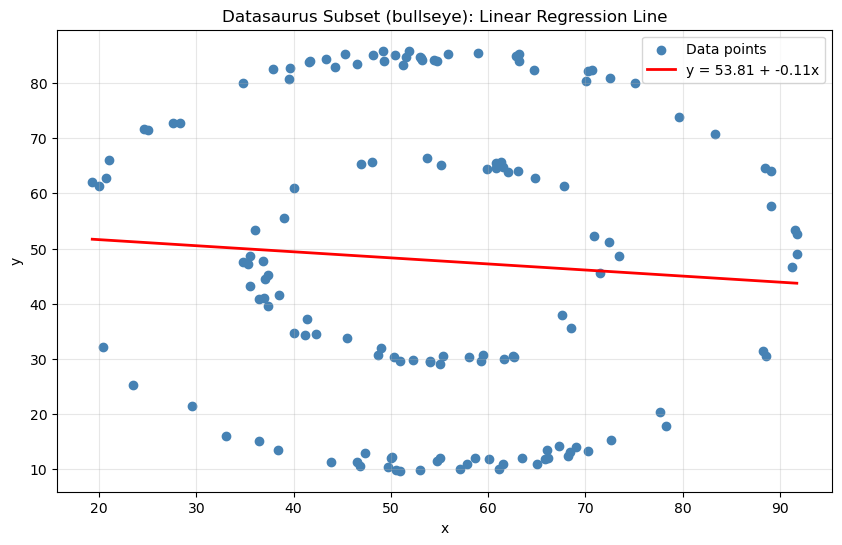

In [144]:
x_line = np.linspace(bullseye["x"].min(), bullseye["x"].max(), 100)
y_line = bullseye_slope[0] + bullseye_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(bullseye["x"], bullseye["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {bullseye_slope[0]:.2f} + {bullseye_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (bullseye): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: slant_up

In [145]:
slant_up = df[df['dataset'] == 'slant_up']
slant_up

,dataset,x,y
1420,slant_up,47.695201,95.241187
1421,slant_up,44.609976,93.075835
1422,slant_up,43.856381,94.085872
1423,slant_up,41.578929,90.303567
1424,slant_up,49.177419,96.610532
...,...,...,...
1557,slant_up,31.333244,32.538569
1558,slant_up,86.401550,38.746933
1559,slant_up,47.442112,98.184302
1560,slant_up,46.264741,94.116192


In [146]:
slant_up_mean_x = compute_mean(slant_up['x'])
slant_up_mean_y = compute_mean(slant_up['y'])
print(f"Mean x: {slant_up_mean_x} | Mean y: {slant_up_mean_y}")

Mean x: 54.26588178560211 | Mean y: 47.83149565202444


In [147]:
slant_up_var_x = compute_sample_variance(slant_up['x'], slant_up_mean_x)
slant_up_var_y = compute_sample_variance(slant_up['y'], slant_up_mean_y)
print(f"Var x: {slant_up_var_x} | Var y: {slant_up_var_y}")

Var x: 281.19441988924456 | Var y: 725.6886047971409


In [148]:
slant_up_pearson_xy = compute_correlation(slant_up["x"], slant_up['y'], slant_up_mean_x, slant_up_mean_y)
print(f"Pearson r: {slant_up_pearson_xy}")

Pearson r: -0.06860920644502215


In [149]:
slant_up_slope = compute_linear_regression(slant_up["x"], slant_up['y'], slant_up_mean_x, slant_up_mean_y)
print(f"Slope: {slant_up_slope}")

Slope: (53.81259564798683, -0.11021842452672188)


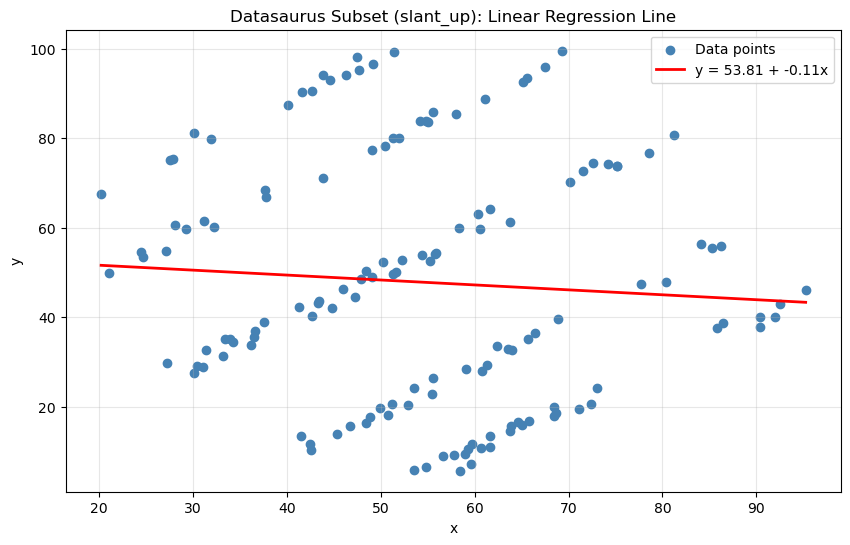

In [150]:
x_line = np.linspace(slant_up["x"].min(), slant_up["x"].max(), 100)
y_line = slant_up_slope[0] + slant_up_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(slant_up["x"], slant_up["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {slant_up_slope[0]:.2f} + {slant_up_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (slant_up): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: slant_down

In [151]:
slant_down = df[df['dataset'] == 'slant_down']
slant_down

,dataset,x,y
1562,slant_down,52.872021,97.343223
1563,slant_down,59.014144,93.574875
1564,slant_down,56.375109,96.305148
1565,slant_down,37.839200,94.359444
1566,slant_down,39.885373,90.634662
...,...,...,...
1699,slant_down,39.596501,32.136132
1700,slant_down,95.593416,33.234129
1701,slant_down,52.772288,99.613472
1702,slant_down,53.178614,98.603861


In [152]:
slant_down_mean_x = compute_mean(slant_down['x'])
slant_down_mean_y = compute_mean(slant_down['y'])
print(f"Mean x: {slant_down_mean_x} | Mean y: {slant_down_mean_y}")

Mean x: 54.2678488233662 | Mean y: 47.835896330588206


In [153]:
slant_down_var_x = compute_sample_variance(slant_down['x'], slant_down_mean_x)
slant_down_var_y = compute_sample_variance(slant_down['y'], slant_down_mean_y)
print(f"Var x: {slant_down_var_x} | Var y: {slant_down_var_y}")

Var x: 281.12420560037276 | Var y: 725.5537488881993


In [154]:
slant_down_pearson_xy = compute_correlation(slant_down["x"], slant_down['y'], slant_down_mean_x, slant_down_mean_y)
print(f"Pearson r: {slant_down_pearson_xy}")

Pearson r: -0.06897973536063173


In [155]:
slant_down_slope = compute_linear_regression(slant_down["x"], slant_down['y'], slant_down_mean_x, slant_down_mean_y)
print(f"Slope: {slant_down_slope}")

Slope: (53.849707743907686, -0.11081720657278205)


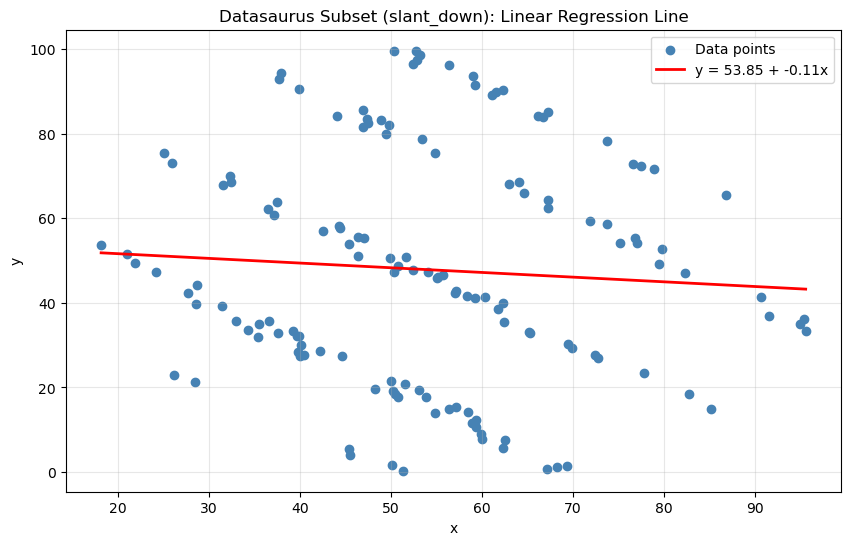

In [156]:
x_line = np.linspace(slant_down["x"].min(), slant_down["x"].max(), 100)
y_line = slant_down_slope[0] + slant_down_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(slant_down["x"], slant_down["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {slant_down_slope[0]:.2f} + {slant_down_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (slant_down): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Stats of subset: wide_lines

In [157]:
wide_lines = df[df['dataset'] == 'wide_lines']
wide_lines

,dataset,x,y
1704,wide_lines,65.815540,95.588374
1705,wide_lines,65.672265,91.933402
1706,wide_lines,39.002716,92.261838
1707,wide_lines,37.795303,93.532455
1708,wide_lines,35.513901,89.599190
...,...,...,...
1841,wide_lines,33.674442,26.090490
1842,wide_lines,75.627255,37.128752
1843,wide_lines,40.610125,89.136240
1844,wide_lines,39.114366,96.481751


In [158]:
wide_lines_mean_x = compute_mean(wide_lines['x'])
wide_lines_mean_y = compute_mean(wide_lines['y'])
print(f"Mean x: {wide_lines_mean_x} | Mean y: {wide_lines_mean_y}")

Mean x: 54.266916301257034 | Mean y: 47.831601988006156


In [159]:
wide_lines_var_x = compute_sample_variance(wide_lines['x'], wide_lines_mean_x)
wide_lines_var_y = compute_sample_variance(wide_lines['y'], wide_lines_mean_y)
print(f"Var x: {wide_lines_var_x} | Var y: {wide_lines_var_y}")

Var x: 281.2328871866248 | Var y: 725.6505602672039


In [160]:
wide_lines_pearson_xy = compute_correlation(wide_lines["x"], wide_lines['y'], wide_lines_mean_x, wide_lines_mean_y)
print(f"Pearson r: {wide_lines_pearson_xy}")

Pearson r: -0.06657523019998104


In [161]:
wide_lines_slope = compute_linear_regression(wide_lines["x"], wide_lines['y'], wide_lines_mean_x, wide_lines_mean_y)
print(f"Slope): {wide_lines_slope}")

Slope): (53.63494893503815, -0.10694079086446209)


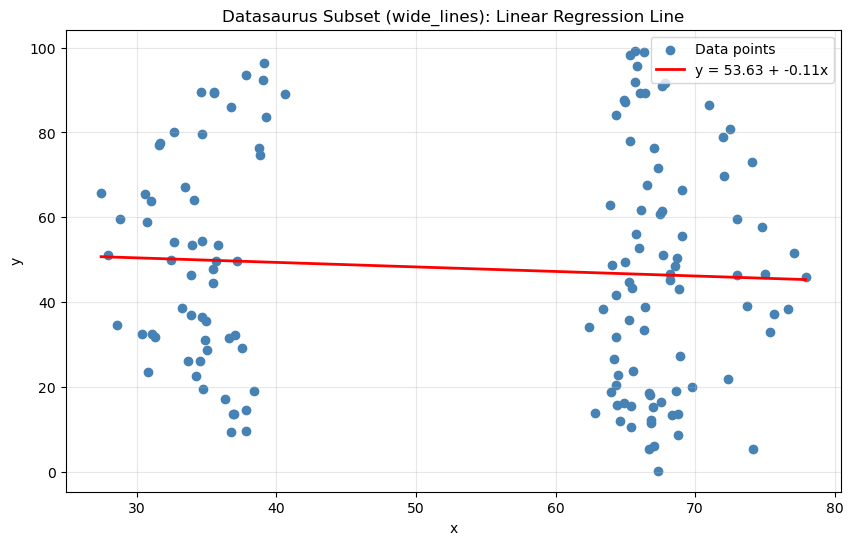

In [162]:
x_line = np.linspace(wide_lines["x"].min(), wide_lines["x"].max(), 100)
y_line = wide_lines_slope[0] + wide_lines_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(wide_lines["x"], wide_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {wide_lines_slope[0]:.2f} + {wide_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus Subset (wide_lines): Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()